# E5

- Même énoncé que l'Exercice 4 mais en considérant l'ensemble des dimensions suivantes:
Day Charge, Eve Charge, Night Charge et CustServ Calls

- Représenter l'ensemble des probabilités produites par le modèle en nuage de point

- Appliquons un threshold T de 0.5

- Décidons que tous les clients ayant une probabilité supérieure à T comme prédits comme 
partant alors qu'à l'inverse, tous les clients ayant une probabilité inférieure à T seront prédits comme restants.

- Calculer alors le nombre de vrais positifs, vrais négatifs, faux positifs et faux négatifs.

- Que pouvez-vous en conclure ?

In [87]:
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

In [88]:
df = pd.read_csv('Churn.txt')


df.head(2)

,State,Account Length,Area Code,Phone,Int'l Plan,VMail Plan,VMail Message,Day Mins,Day Calls,Day Charge,...,Eve Calls,Eve Charge,Night Mins,Night Calls,Night Charge,Intl Mins,Intl Calls,Intl Charge,CustServ Calls,Churn?
0,KS,128,415,382-4657,no,yes,25,265.1,110,45.07,...,99,16.78,244.7,91,11.01,10.0,3,2.7,1,False.
1,OH,107,415,371-7191,no,yes,26,161.6,123,27.47,...,103,16.62,254.4,103,11.45,13.7,3,3.7,1,False.


In [89]:
sub_df = df[['Day Charge','Eve Charge','Night Charge','CustServ Calls','Churn?']].copy()

def transform(x):
    if x == 'False.':
        return 0
    else:
        return 1

sub_df['target'] = sub_df['Churn?'].apply(transform)

# Plusieurs variables explicatives
X = sub_df[[ 'Day Charge', 'Eve Charge', 'Night Charge', 'CustServ Calls']]

# Variable expliquée
y = sub_df['target']

model = LogisticRegression()
model.fit(X, y)

model_df = pd.DataFrame()
model_df['target'] = y

# On prend la probabilité qu'ils partent
model_df['proba'] = model.predict_proba(X)[:,1]

model_df

,target,proba
0,0,0.236297
1,0,0.081092
2,0,0.072295
3,0,0.221179
4,0,0.125557
...,...,...
3328,0,0.133722
3329,0,0.247865
3330,0,0.207511
3331,0,0.135061


Modèle en nuage de points

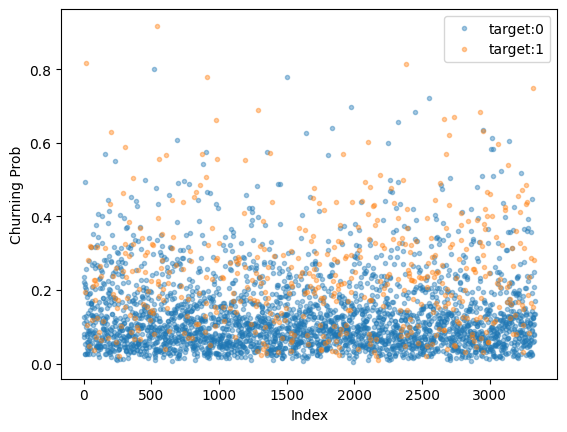

In [90]:
for target in [0,1]:
    # On met en confrontation la probabilité du modèle et le départ réel
    temp_df = model_df[model_df['target']==target]
    plt.plot(temp_df['proba'], '.', alpha=0.4, label='target:{}'.format(target))

plt.xlabel('Index')
plt.ylabel('Churning Prob')
plt.legend()
plt.show()

On applique un treshold de 0.5

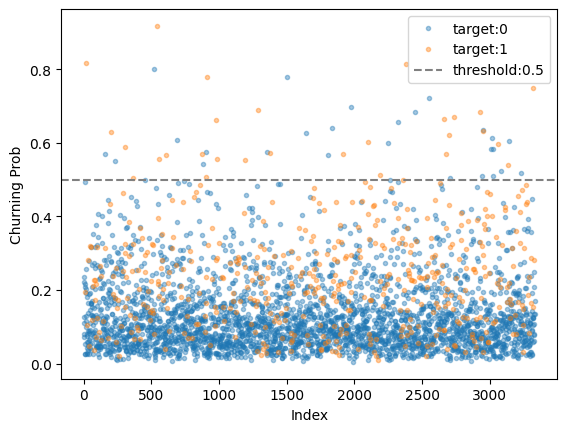

In [91]:
T = 0.5

for target in [0,1]:
    temp_df = model_df[model_df['target']==target]
    plt.plot(temp_df['proba'], '.', alpha=0.4, label='target:{}'.format(target))
    
plt.axhline(T, color='grey', linestyle='--',label='threshold:{}'.format(T))
plt.xlabel('Index')
plt.ylabel('Churning Prob')
plt.legend()
plt.show()

Au dessus du seuil, nous aurons:
- Vrai positifs (Prob qu'ils partent et ils partent) - VP
- Faux positifs (Prob qu'ils partent mais ils restent) - FP

En dessous du seuil, nous aurons:
- Vrai négatifs (Prob qu'ils restent et ils restent) - VN
- Faux négatifs (Prob qu'ils restent et ils partent) - FN

In [92]:
TP = model_df[(model_df['target']==1)&(model_df['proba']>T)].shape[0]
FP = model_df[(model_df['target']==0)&(model_df['proba']>T)].shape[0]
FN = model_df[(model_df['target']==1)&(model_df['proba']<T)].shape[0]
TN = model_df[(model_df['target']==0)&(model_df['proba']<T)].shape[0]

print('VP:{} FP:{}'.format(TP, FP))
print('FN:{} VN:{}'.format(FN, TN))

VP:28 FP:26
FN:455 VN:2824


# E6

modifier le seuil de l'exercice précédent et reporter les valeurs de la sensibilité et de la spécificité dans un même graphe

Que ce passe-t-il si on varie cette valeur dans l'intervalle [0,1] ?  
En vue statique, matplotlib, nous aurons: 

In [93]:
threshold_list = np.linspace(0,1,51)

score_df = pd.DataFrame()
score_df['threshold'] = threshold_list

TP_list = []
FP_list = []
TN_list = []
FN_list = []
for threshold in threshold_list:
    TP = model_df[(model_df['target']==1) & (model_df['proba']>threshold)].shape[0]
    FP = model_df[(model_df['target']==0) & (model_df['proba']>threshold)].shape[0]
    TN = model_df[(model_df['target']==0) & (model_df['proba']<threshold)].shape[0]
    FN = model_df[(model_df['target']==1) & (model_df['proba']<threshold)].shape[0]
    TP_list.append(TP)
    FP_list.append(FP)
    TN_list.append(TN)
    FN_list.append(FN)

score_df['VP'] = TP_list
score_df['FP'] = FP_list
score_df['VN'] = TN_list
score_df['FN'] = FN_list

score_df.head()

,threshold,VP,FP,VN,FN
0,0.00,483,2850,0,0
1,0.02,480,2783,67,3
2,0.04,463,2509,341,20
3,0.06,441,2136,714,42
4,0.08,416,1766,1084,67


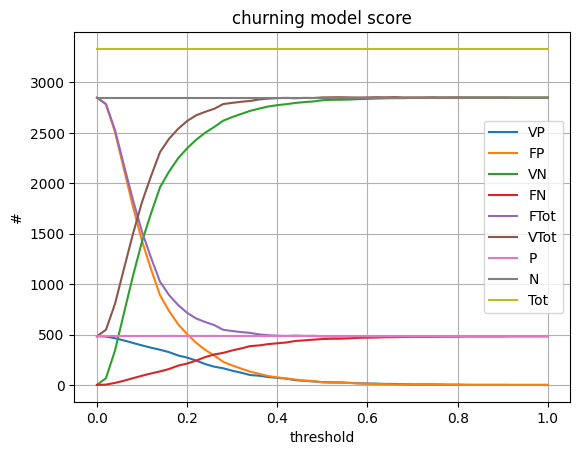

In [ ]:
 # total des faux (positifs et négatifs)
score_df['FTot'] = score_df['FP'] + score_df['FN']

# total des vrais (positifs et négatifs)
score_df['VTot'] = score_df['VP'] + score_df['VN']

score_df['Tot'] = score_df['FTot'] + score_df['VTot']

score_df['P'] = score_df['VP'] + score_df['FN']
score_df['N'] = score_df['VN'] + score_df['FP']

for genre in ['VP', 'FP', 'VN', 'FN','FTot','VTot','P','N','Tot']:
    plt.plot(score_df['threshold'], score_df[genre], label=genre)
    
plt.xlabel('threshold')
plt.ylabel('#')
plt.title('churning model score')
plt.legend()
plt.grid()
plt.show()

Jusqu'ici, nous avons considéré les nombres (TP, FP, FN, TN) constituant la matrice de confusion.  
Ces nombres étant absolus, ils ne seront pas 'portables' d'expérience en expérience...
C'est pourquoi on préfère généralement utiliser des scores reprenant des chiffres relatifs
tous dans l'intervalle [0,1] comme la précision, l'exactitude, la spécificité et la sensibilité (voir tableau de synthèse dans les slides)  

In [95]:
score_df['specificity'] = score_df.apply(lambda r:r['VN']/(r['FP']+r['VN']), axis=1)
score_df['sensitivity'] = score_df.apply(lambda r:r['VP']/(r['VP']+r['FN']), axis=1)
score_df['precision'] = score_df.apply(lambda r:r['VP']/(r['VP']+r['FP']) if r['VP']+r['FP']!=0 else None, axis=1)
score_df['accuracy'] = score_df.apply(lambda r:(r['VP']+r['VN'])/(r['VP']+r['FP']+r['VN']+r['FN']), axis=1)

Les formules pour les deux autres scores (precision et accuracy) sont tirées de https://en.wikipedia.org/wiki/Confusion_matrix

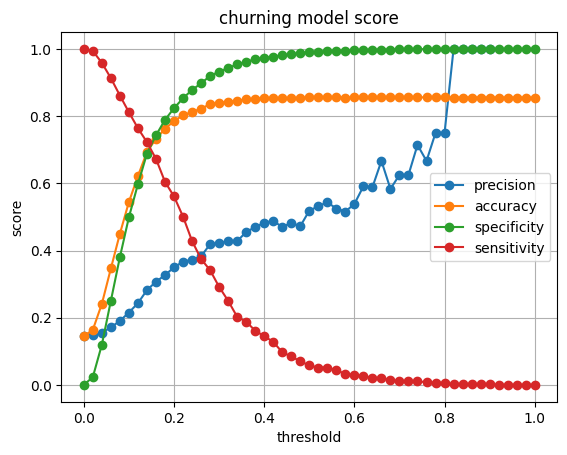

In [96]:
for genre in ['precision','accuracy','specificity','sensitivity']:
    plt.plot(score_df['threshold'], score_df[genre], '-o', label=genre)
    
plt.xlabel('threshold')
plt.ylabel('score')
plt.title('churning model score')
plt.legend()
plt.grid()
plt.show()

En particulier, on va se concentrer sur deux scores, l'anti-spécificité (1-spécificité) et la sensibilité, 
l'un reporté sur l'axe des x et l'autre sur l'axe des y.  
On obtient alors la vue statique suivante:  

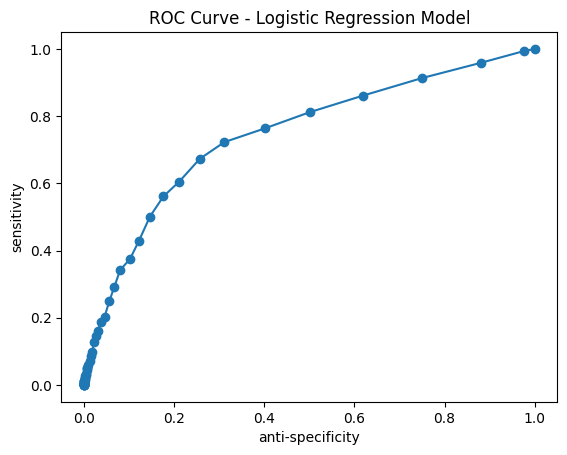

In [97]:
plt.plot(1-score_df['specificity'], score_df['sensitivity'], '-o')
plt.xlabel('anti-specificity')
plt.ylabel('sensitivity')
plt.title('ROC Curve - Logistic Regression Model')
plt.show()

L'accumulation de points au voisinage de (0,0) vous semble-t-elle logique? et pourquoi?  

Généralement, on s'arrange pour les axes x et y soit à la même échelle (aspect ratio == 1).

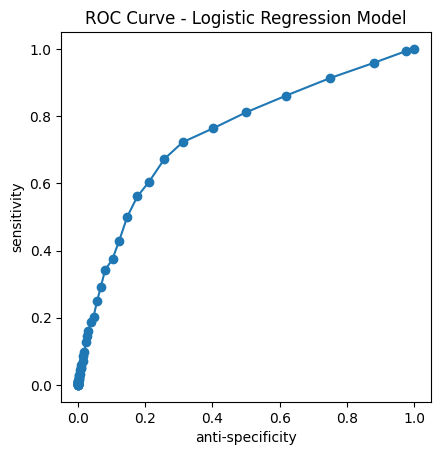

In [98]:
plt.axes().set_aspect('equal')
plt.plot(1-score_df['specificity'], score_df['sensitivity'], '-o')
plt.xlabel('anti-specificity')
plt.ylabel('sensitivity')
plt.title('ROC Curve - Logistic Regression Model')
plt.show()

In [99]:
print('{:.3f}'.format(roc_auc_score(model_df['target'], model_df['proba'])))

0.745


Dans la même foulée que précédemment, on peut aussi ajouter la courbe ainsi obtenue à notre vue interactive précédente,  
pour obtenir finalement: